# Phase 2b: Baseline IDS - Support Vector Machine
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Trains on the **balanced** training set and evaluates on the **untouched** validation and test sets.
Run Phase 1, Phase 1b and (optionally) Phase 2a first.

**Why LinearSVC:** a kernel `SVC` scales roughly quadratically with the number of samples and is impractical on several hundred thousand rows. `LinearSVC` solves the same linear-kernel SVM (the configuration used in the reference paper) in minutes.

## Step 0: Imports and settings

In [1]:
import os, json, time
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
print("Setup done")

Setup done


## Step 1: Load data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")

for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Train the linear SVM

In [3]:
svm = LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=42)

t0 = time.time()
svm.fit(X_train, y_train)
train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

joblib.dump(svm, f"{MODEL_DIR}/svm_linear_baseline.joblib")

Training time: 214.8 s


['models/svm_linear_baseline.joblib']

## Step 3: Evaluation function
The SVM has no probabilities by default, so ROC-AUC uses the signed distance to the hyperplane (`decision_function`).

In [4]:
def evaluate(model, X, y, name):
    y_pred = model.predict(X)
    score = model.decision_function(X)
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y, y_pred),
        "precision":   precision_score(y, y_pred, zero_division=0),
        "recall":      recall_score(y, y_pred),
        "f1":          f1_score(y, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y, score),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred, score

## Step 4: Results on validation and test sets

In [5]:
val_m,  val_pred,  val_score  = evaluate(svm, X_val,  y_val,  "validation")
test_m, test_pred, test_score = evaluate(svm, X_test, y_test, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.7948       0.7955
precision            0.4512       0.4521
recall               0.9938       0.9938
f1                   0.6207       0.6215
specificity          0.7544       0.7553
fpr                  0.2456       0.2447
fnr                  0.0062       0.0062
roc_auc              0.9754       0.9759

Test classification report:
              precision    recall  f1-score   support

      Benign     0.9983    0.7553    0.8600    314259
      Attack     0.4521    0.9938    0.6215     63861

    accuracy                         0.7955    378120
   macro avg     0.7252    0.8745    0.7407    378120
weighted avg     0.9061    0.7955    0.8197    378120



## Step 5: Confusion matrix and ROC curve (test set)

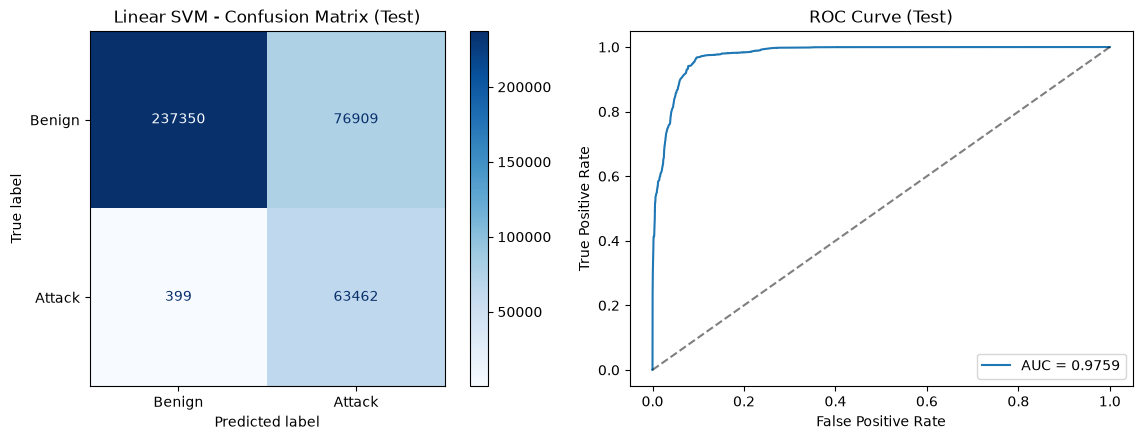

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("Linear SVM - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_score)
ax[1].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/svm_clean_cm_roc.png", dpi=150)
plt.show()

## Step 6: Save results

In [7]:
with open(f"{RESULT_DIR}/svm_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time}, f, indent=2)
print("Saved:", sorted(os.listdir(RESULT_DIR)))

Saved: ['logreg_clean_cm_roc.png', 'logreg_clean_metrics.json', 'svm_clean_cm_roc.png', 'svm_clean_metrics.json']


## Step 7: Compare with Logistic Regression (if Phase 2a was run)

In [8]:
path_lr = f"{RESULT_DIR}/logreg_clean_metrics.json"
if os.path.exists(path_lr):
    lr = json.load(open(path_lr))["test"]
    print(f"{'Metric':14s} {'LogReg':>10s} {'LinearSVM':>10s}")
    for k in keys:
        print(f"{k:14s} {lr[k]:10.4f} {test_m[k]:10.4f}")
else:
    print("Run Phase 2a first to see the comparison.")

Metric             LogReg  LinearSVM
accuracy           0.7908     0.7955
precision          0.4464     0.4521
recall             0.9951     0.9938
f1                 0.6163     0.6215
specificity        0.7493     0.7553
fpr                0.2507     0.2447
fnr                0.0049     0.0062
roc_auc            0.9745     0.9759


## Step 8 (optional): RBF-kernel SVM on a subsample
A kernel SVM cannot handle the full training set, so this trains on a random 50,000-row sample. Set `RUN_RBF = True` to run it (can take several minutes). Report it as a subsample result, since it sees far less data than the other models.

In [ ]:
RUN_RBF = False

if RUN_RBF:
    from sklearn.svm import SVC
    rng = np.random.RandomState(42)
    idx = rng.choice(len(X_train), size=50_000, replace=False)
    t0 = time.time()
    rbf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42).fit(X_train[idx], y_train[idx])
    print(f"RBF training time: {time.time() - t0:.1f} s")
    rbf_m, _, _ = evaluate(rbf, X_test, y_test, "test")
    for k in keys:
        print(f"{k:14s} {rbf_m[k]:.4f}")
    joblib.dump(rbf, f"{MODEL_DIR}/svm_rbf_subsample.joblib")

## Notes for the report
- A linear SVM is differentiable with respect to its input (the gradient is the weight vector `svm.coef_`), so FGSM and PGD can be applied to it directly in Phase 3.
- Compare **FNR** across models: missed attacks are what adversarial evasion will try to increase.